In [1]:

from pathlib import Path
import pandas as pd
import json
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\Users\S_Gayathri\skill-gap-analyzer")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

resumes = pd.read_csv(PROCESSED_DIR / "resumes_with_skills.csv")
jobs = pd.read_csv(PROCESSED_DIR / "jobs_with_skills.csv")

def parse_skills(value):
    if pd.isna(value):
        return []
    try:
        result = json.loads(value)
        return result if isinstance(result, list) else []
    except (json.JSONDecodeError, TypeError):
        return []

resumes["extracted_skills"] = resumes["extracted_skills_json"].apply(parse_skills)
jobs["extracted_skills"] = jobs["extracted_skills_json"].apply(parse_skills)

print("Resumes:", resumes.shape)
print("Jobs:", jobs.shape)
print("Data loaded successfully!")


Resumes: (2484, 6)
Jobs: (20000, 7)
Data loaded successfully!


In [2]:

LEARNING_RESOURCES = {
    "python": {
        "level": "Beginner to Intermediate",
        "resource": "Python Official Tutorial",
        "url": "https://docs.python.org/3/tutorial/"
    },
    "sql": {
        "level": "Beginner",
        "resource": "SQLBolt Interactive Lessons",
        "url": "https://sqlbolt.com/"
    },
    "machine learning": {
        "level": "Intermediate",
        "resource": "Scikit-learn Tutorials",
        "url": "https://scikit-learn.org/stable/tutorial/index.html"
    },
    "deep learning": {
        "level": "Intermediate",
        "resource": "DeepLearning.AI",
        "url": "https://www.deeplearning.ai/"
    },
    "natural language processing": {
        "level": "Intermediate",
        "resource": "Hugging Face NLP Course",
        "url": "https://huggingface.co/learn/nlp-course/"
    },
    "generative ai": {
        "level": "Intermediate",
        "resource": "Google Cloud Generative AI Learning",
        "url": "https://www.cloudskillsboost.google/"
    },
    "large language models": {
        "level": "Intermediate",
        "resource": "Hugging Face LLM Course",
        "url": "https://huggingface.co/learn"
    },
    "langchain": {
        "level": "Intermediate",
        "resource": "LangChain Documentation",
        "url": "https://python.langchain.com/docs/"
    },
    "langgraph": {
        "level": "Intermediate",
        "resource": "LangGraph Documentation",
        "url": "https://docs.langchain.com/oss/python/langgraph/overview"
    },
    "retrieval augmented generation": {
        "level": "Intermediate",
        "resource": "RAG Tutorial",
        "url": "https://huggingface.co/learn"
    },
    "tensorflow": {
        "level": "Intermediate",
        "resource": "TensorFlow Tutorials",
        "url": "https://www.tensorflow.org/tutorials"
    },
    "pytorch": {
        "level": "Intermediate",
        "resource": "PyTorch Tutorials",
        "url": "https://pytorch.org/tutorials/"
    },
    "pandas": {
        "level": "Beginner to Intermediate",
        "resource": "Pandas Getting Started",
        "url": "https://pandas.pydata.org/docs/getting_started/"
    },
    "numpy": {
        "level": "Beginner",
        "resource": "NumPy Tutorials",
        "url": "https://numpy.org/learn/"
    },
    "data analysis": {
        "level": "Beginner to Intermediate",
        "resource": "Kaggle Learn",
        "url": "https://www.kaggle.com/learn"
    },
    "data visualization": {
        "level": "Beginner to Intermediate",
        "resource": "Matplotlib Tutorials",
        "url": "https://matplotlib.org/stable/tutorials/"
    },
    "flask": {
        "level": "Beginner to Intermediate",
        "resource": "Flask Documentation",
        "url": "https://flask.palletsprojects.com/"
    },
    "fastapi": {
        "level": "Intermediate",
        "resource": "FastAPI Tutorial",
        "url": "https://fastapi.tiangolo.com/tutorial/"
    },
    "streamlit": {
        "level": "Beginner to Intermediate",
        "resource": "Streamlit Documentation",
        "url": "https://docs.streamlit.io/"
    },
    "computer vision": {
        "level": "Intermediate",
        "resource": "OpenCV Tutorials",
        "url": "https://docs.opencv.org/"
    },
    "git": {
        "level": "Beginner",
        "resource": "Git Book",
        "url": "https://git-scm.com/book/en/v2"
    },
    "docker": {
        "level": "Intermediate",
        "resource": "Docker Get Started",
        "url": "https://docs.docker.com/get-started/"
    },
    "aws": {
        "level": "Intermediate",
        "resource": "AWS Skill Builder",
        "url": "https://skillbuilder.aws/"
    },
    "azure": {
        "level": "Intermediate",
        "resource": "Microsoft Learn",
        "url": "https://learn.microsoft.com/training/"
    },
    "javascript": {
        "level": "Beginner to Intermediate",
        "resource": "MDN JavaScript Guide",
        "url": "https://developer.mozilla.org/en-US/docs/Web/JavaScript/Guide"
    },
    "java": {
        "level": "Beginner to Intermediate",
        "resource": "Dev.java Learning",
        "url": "https://dev.java/learn/"
    },
    "statistics": {
        "level": "Beginner to Intermediate",
        "resource": "Khan Academy Statistics",
        "url": "https://www.khanacademy.org/math/statistics-probability"
    },
    "transformers": {
        "level": "Intermediate",
        "resource": "Hugging Face Transformers Course",
        "url": "https://huggingface.co/learn"
    },
    "vector databases": {
        "level": "Intermediate",
        "resource": "Chroma Documentation",
        "url": "https://docs.trychroma.com/"
    },
    "api development": {
        "level": "Intermediate",
        "resource": "FastAPI Tutorial",
        "url": "https://fastapi.tiangolo.com/tutorial/"
    }
}

print("Available learning recommendations:", len(LEARNING_RESOURCES))


Available learning recommendations: 30


In [3]:

def analyze_skill_gap(user_skills, required_skills):
    user_set = {str(skill).lower() for skill in user_skills}
    required_set = {str(skill).lower() for skill in required_skills}

    matched = sorted(user_set & required_set)
    missing = sorted(required_set - user_set)

    total_required = len(required_set)

    coverage = (
        round(len(matched) / total_required * 100, 2)
        if total_required else 0.0
    )

    return {
        "matched_skills": matched,
        "missing_skills": missing,
        "total_required": total_required,
        "matched_count": len(matched),
        "missing_count": len(missing),
        "coverage_percentage": coverage
    }

# Test with example data
test_result = analyze_skill_gap(
    ["python", "sql", "pandas"],
    ["python", "sql", "machine learning", "pandas", "fastapi"]
)

test_result


{'matched_skills': ['pandas', 'python', 'sql'],
 'missing_skills': ['fastapi', 'machine learning'],
 'total_required': 5,
 'matched_count': 3,
 'missing_count': 2,
 'coverage_percentage': 60.0}

In [4]:

def recommend_learning(missing_skills):
    recommendations = []

    for skill in missing_skills:
        info = LEARNING_RESOURCES.get(
            skill.lower(),
            {
                "level": "To be determined",
                "resource": "Search for a course or tutorial",
                "url": "https://www.coursera.org/"
            }
        )

        recommendations.append({
            "skill": skill,
            "level": info["level"],
            "resource": info["resource"],
            "url": info["url"]
        })

    return recommendations

recommend_learning(test_result["missing_skills"])


[{'skill': 'fastapi',
  'level': 'Intermediate',
  'resource': 'FastAPI Tutorial',
  'url': 'https://fastapi.tiangolo.com/tutorial/'},
 {'skill': 'machine learning',
  'level': 'Intermediate',
  'resource': 'Scikit-learn Tutorials',
  'url': 'https://scikit-learn.org/stable/tutorial/index.html'}]

In [5]:

resume_candidates = resumes[
    resumes["extracted_skills"].apply(len) > 0
]

job_candidates = jobs[
    jobs["extracted_skills"].apply(len) > 0
]

if resume_candidates.empty:
    raise ValueError(
        "No resume skills were extracted. Review Step 3 and the skill dictionary."
    )

if job_candidates.empty:
    raise ValueError(
        "No job skills were extracted. Review Step 3 and the skill dictionary."
    )

selected_resume = resume_candidates.iloc[0]
selected_job = job_candidates.iloc[0]

print("Resume ID:", selected_resume["ID"])
print("Resume category:", selected_resume["Category"])
print("Job title:", selected_job["title"])

print("\nResume skills:", selected_resume["extracted_skills"])
print("Required skills:", selected_job["extracted_skills"])


Resume ID: 16852973
Resume category: HR
Job title: Economic Development and Planning Intern

Resume skills: ['data analysis', 'statistics']
Required skills: ['data analysis']


In [6]:

analysis = analyze_skill_gap(
    selected_resume["extracted_skills"],
    selected_job["extracted_skills"]
)

recommendations = recommend_learning(analysis["missing_skills"])

print("JOB:", selected_job["title"])
print("\nMatched skills:", analysis["matched_skills"])
print("Missing skills:", analysis["missing_skills"])
print("Skill coverage:", f'{analysis["coverage_percentage"]}%')

print("\nPersonalized learning recommendations:")
display(pd.DataFrame(recommendations))


JOB: Economic Development and Planning Intern

Matched skills: ['data analysis']
Missing skills: []
Skill coverage: 100.0%

Personalized learning recommendations:


""


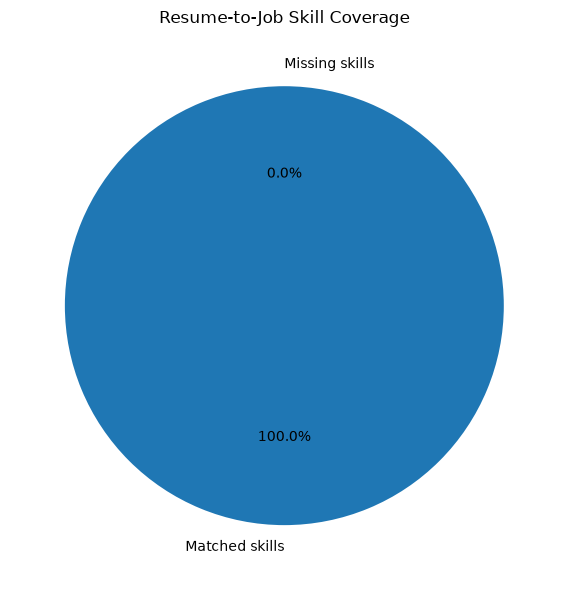

Chart saved: C:\Users\S_Gayathri\skill-gap-analyzer\reports\skill_gap_coverage.png


In [7]:

matched_count = analysis["matched_count"]
missing_count = analysis["missing_count"]

plt.figure(figsize=(6, 6))
plt.pie(
    [matched_count, missing_count],
    labels=["Matched skills", "Missing skills"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Resume-to-Job Skill Coverage")
plt.tight_layout()

chart_path = REPORTS_DIR / "skill_gap_coverage.png"
plt.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)


In [8]:

report = {
    "resume_id": str(selected_resume["ID"]),
    "resume_category": str(selected_resume["Category"]),
    "job_id": str(selected_job["job_id"]),
    "job_title": str(selected_job["title"]),
    **analysis,
    "recommendations": recommendations
}

report_path = REPORTS_DIR / "sample_skill_gap_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=4, ensure_ascii=False)

print("Analysis saved to:", report_path)


Analysis saved to: C:\Users\S_Gayathri\skill-gap-analyzer\reports\sample_skill_gap_report.json
